In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from scipy.sparse import hstack, csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

df = pd.read_csv("Symptom2Disease.csv")
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (1200, 3)


,Unnamed: 0,label,text
0,0,Psoriasis,I have been experiencing a skin rash on my arm...
1,1,Psoriasis,"My skin has been peeling, especially on my kne..."
2,2,Psoriasis,I have been experiencing joint pain in my fing...
3,3,Psoriasis,"There is a silver like dusting on my skin, esp..."
4,4,Psoriasis,"My nails have small dents or pits in them, and..."


In [3]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
df["label"] = df["label"].str.strip().str.title()
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

URGENCY_MAP = {
    "Pneumonia": "High Priority",
    "Dengue": "High Priority",
    "Malaria": "High Priority",
    "Typhoid": "High Priority",
    "Bronchial Asthma": "High Priority",
    "Hypertension": "High Priority",
    "Jaundice": "Moderate",
    "Urinary Tract Infection": "Moderate",
    "Diabetes": "Moderate",
    "Peptic Ulcer Disease": "Moderate",
    "Gastroesophageal Reflux Disease": "Moderate",
    "Drug Reaction": "Moderate",
    "Chicken Pox": "Moderate",
    "Migraine": "Moderate",
    "Cervical Spondylosis": "Moderate",
    "Common Cold": "Low",
    "Allergy": "Low",
    "Fungal Infection": "Low",
    "Acne": "Low",
    "Psoriasis": "Low",
    "Impetigo": "Low",
    "Varicose Veins": "Low",
    "Arthritis": "Low",
    "Dimorphic Hemorrhoids": "Low",
}

df["urgency"] = df["label"].map(URGENCY_MAP)
print("Cleaned Rows:", len(df))
print("\nUrgency Tier Counts:\n", df["urgency"].value_counts())

Cleaned Rows: 1153

Urgency Tier Counts:
 urgency
Low              432
Moderate         431
High Priority    290
Name: count, dtype: int64


In [4]:
stop_words = set(stopwords.words("english")) - {"no", "not", "nor", "never", "without", "cannot"}
lemmatizer = WordNetLemmatizer()

def clean_clinical_text(text):
    words = "".join(ch if ch.isalpha() or ch.isspace() else " " for ch in str(text).lower()).split()
    cleaned = [lemmatizer.lemmatize(w) for w in words if w not in stop_words and len(w) > 1]
    return " ".join(cleaned)

df["clean_text"] = df["text"].apply(clean_clinical_text)
df[["label", "urgency", "clean_text"]].head()

,label,urgency,clean_text
0,Psoriasis,Low,experiencing skin rash arm leg torso past week...
1,Psoriasis,Low,skin peeling especially knee elbow scalp peeli...
2,Psoriasis,Low,experiencing joint pain finger wrist knee pain...
3,Psoriasis,Low,silver like dusting skin especially lower back...
4,Psoriasis,Low,nail small dent pit often feel inflammatory te...


In [5]:
RED_FLAG_KEYWORDS = {
    "flag_breathing": ["breath", "breathing", "wheez", "suffocat", "shortness"],
    "flag_chest_pain": ["chest pain", "chest hurt", "heart racing", "palpitation"],
    "flag_high_fever": ["high fever", "high temperature", "chill", "shiver"],
    "flag_neuro": ["dizzy", "dizziness", "vomit", "blur", "migraine", "unconscious"],
    "flag_skin_rash": ["rash", "peel", "blister", "itch", "scale", "red spot"],
}

def extract_red_flags(text_series):
    flag_matrix = pd.DataFrame()
    lower_series = text_series.str.lower()
    for col, keywords in RED_FLAG_KEYWORDS.items():
        flag_matrix[col] = lower_series.apply(lambda t: int(any(kw in t for kw in keywords)))
    return csr_matrix(flag_matrix.values)

X_train_raw, X_test_raw, y_dis_train, y_dis_test, y_urg_train, y_urg_test = train_test_split(
    df["clean_text"],
    df["label"],
    df["urgency"],
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=1500, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(X_train_raw)
X_test_tfidf = tfidf.transform(X_test_raw)

X_train = hstack([X_train_tfidf, extract_red_flags(X_train_raw)])
X_test = hstack([X_test_tfidf, extract_red_flags(X_test_raw)])

disease_encoder = LabelEncoder()
urgency_encoder = LabelEncoder()

y_dis_train_enc = disease_encoder.fit_transform(y_dis_train)
y_dis_test_enc = disease_encoder.transform(y_dis_test)

y_urg_train_enc = urgency_encoder.fit_transform(y_urg_train)
y_urg_test_enc = urgency_encoder.transform(y_urg_test)

print("Training Matrix Shape:", X_train.shape)
print("Testing Matrix Shape:", X_test.shape)

Training Matrix Shape: (922, 1505)
Testing Matrix Shape: (231, 1505)


In [6]:
def rule_based_urgency_baseline(text_series):
    preds = []
    high_terms = ["chest", "breath", "high fever", "heart", "wheez", "temperature", "chill"]
    mod_terms = ["pain", "vomit", "dizzy", "urine", "yellow", "stomach", "headache", "migraine"]
    for text in text_series:
        t = text.lower()
        if any(term in t for term in high_terms):
            preds.append("High Priority")
        elif any(term in t for term in mod_terms):
            preds.append("Moderate")
        else:
            preds.append("Low")
    return preds

baseline_preds = rule_based_urgency_baseline(X_test_raw)

rf_urgency = RandomForestClassifier(n_estimators=200, random_state=42)
rf_urgency.fit(X_train, y_urg_train_enc)
rf_urg_preds = urgency_encoder.inverse_transform(rf_urgency.predict(X_test))

xgb_urgency = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, random_state=42, eval_metric="mlogloss")
xgb_urgency.fit(X_train, y_urg_train_enc)
xgb_urg_preds = urgency_encoder.inverse_transform(xgb_urgency.predict(X_test))

rf_disease = RandomForestClassifier(n_estimators=250, random_state=42)
rf_disease.fit(X_train, y_dis_train_enc)
rf_dis_preds = disease_encoder.inverse_transform(rf_disease.predict(X_test))

def get_metrics(y_true, y_pred, model_name):
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {"Model": model_name, "Accuracy": round(acc, 4), "Precision": round(prec, 4), "Recall": round(rec, 4), "F1-Score": round(f1, 4)}

results_df = pd.DataFrame([
    get_metrics(y_urg_test, baseline_preds, "Rule-Based Baseline (Urgency)"),
    get_metrics(y_urg_test, rf_urg_preds, "Random Forest (Urgency)"),
    get_metrics(y_urg_test, xgb_urg_preds, "XGBoost (Urgency)"),
    get_metrics(y_dis_test, rf_dis_preds, "Random Forest (24-Disease Classifier)")
])

results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Rule-Based Baseline (Urgency),0.5455,0.5492,0.5455,0.5372
1,Random Forest (Urgency),0.9697,0.9705,0.9697,0.9696
2,XGBoost (Urgency),0.9264,0.9274,0.9264,0.9266
3,Random Forest (24-Disease Classifier),0.9394,0.9459,0.9394,0.9366


In [7]:
def predict_patient_triage(symptom_text):
    cleaned = clean_clinical_text(symptom_text)
    vec = tfidf.transform([cleaned])
    flags = extract_red_flags(pd.Series([cleaned]))
    features = hstack([vec, flags])

    urg_idx = rf_urgency.predict(features)[0]
    predicted_urgency = urgency_encoder.inverse_transform([urg_idx])[0]

    dis_probs = rf_disease.predict_proba(features)[0]
    top3_idx = np.argsort(dis_probs)[::-1][:3]
    top3_conditions = [
        {"condition": disease_encoder.inverse_transform([i])[0], "confidence": round(float(dis_probs[i]) * 100, 1)}
        for i in top3_idx
    ]

    return {
        "suggested_urgency": predicted_urgency,
        "candidate_conditions": top3_conditions
    }

sample_input = "I have a very high fever since last night, severe chills, body aches, and pain behind my eyes."
predict_patient_triage(sample_input)

{'suggested_urgency': 'High Priority',
 'candidate_conditions': [{'condition': 'Dengue', 'confidence': 43.2},
  {'condition': 'Typhoid', 'confidence': 15.6},
  {'condition': 'Chicken Pox', 'confidence': 6.8}]}

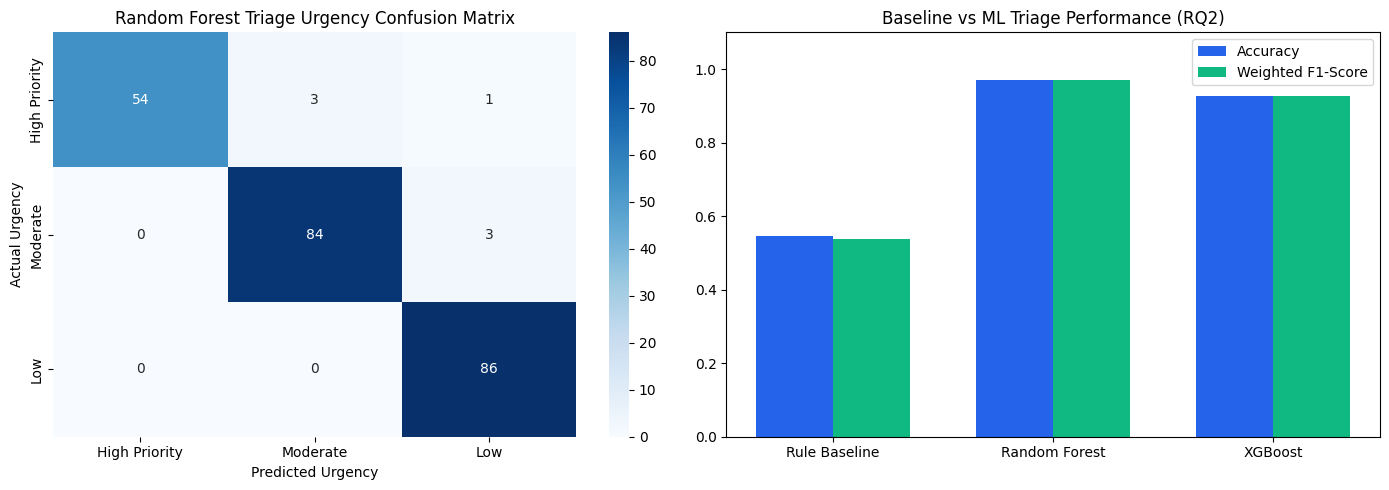


Detailed Urgency Classification Report (Random Forest):

               precision    recall  f1-score   support

High Priority       1.00      0.93      0.96        58
          Low       0.96      1.00      0.98        86
     Moderate       0.97      0.97      0.97        87

     accuracy                           0.97       231
    macro avg       0.97      0.97      0.97       231
 weighted avg       0.97      0.97      0.97       231



In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

labels_order = ["High Priority", "Moderate", "Low"]
cm = confusion_matrix(y_urg_test, rf_urg_preds, labels=labels_order)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels_order, yticklabels=labels_order, ax=axes[0])
axes[0].set_title("Random Forest Triage Urgency Confusion Matrix")
axes[0].set_xlabel("Predicted Urgency")
axes[0].set_ylabel("Actual Urgency")

urg_comp = results_df.iloc[:3]
x = np.arange(len(urg_comp["Model"]))
width = 0.35
axes[1].bar(x - width/2, urg_comp["Accuracy"], width, label="Accuracy", color="#2563eb")
axes[1].bar(x + width/2, urg_comp["F1-Score"], width, label="Weighted F1-Score", color="#10b981")
axes[1].set_xticks(x)
axes[1].set_xticklabels(["Rule Baseline", "Random Forest", "XGBoost"])
axes[1].set_ylim(0, 1.1)
axes[1].set_title("Baseline vs ML Triage Performance (RQ2)")
axes[1].legend()

plt.tight_layout()
plt.savefig("triage_evaluation_charts.png", dpi=300)
plt.show()

print("\nDetailed Urgency Classification Report (Random Forest):\n")
print(classification_report(y_urg_test, rf_urg_preds))

In [9]:
model_bundle = {
    "tfidf": tfidf,
    "urgency_model": rf_urgency,
    "disease_model": rf_disease,
    "urgency_encoder": urgency_encoder,
    "disease_encoder": disease_encoder,
    "red_flag_keywords": RED_FLAG_KEYWORDS,
    "stop_words": stop_words
}

joblib.dump(model_bundle, "triage_model_bundle.joblib")
print("Exported triage_model_bundle.joblib successfully! Ready for FastAPI backend.")

Exported triage_model_bundle.joblib successfully! Ready for FastAPI backend.


In [10]:
lower_series = df["clean_text"].str.lower()
for col, keywords in RED_FLAG_KEYWORDS.items():
    df[col] = lower_series.apply(lambda t: int(any(kw in t for kw in keywords)))

df.to_csv("cleaned_Symptom2Disease.csv", index=False)
print("Saved cleaned_Symptom2Disease.csv:", df.shape)

Saved cleaned_Symptom2Disease.csv: (1153, 9)
